# 03 - TESPy: how efficient is the heat pump?

[TESPy](https://tespy.readthedocs.io) builds thermodynamic cycles out of
components (compressor, valve, heat exchangers) and solves them with real
fluid properties (from CoolProp).

What I need from it for this project is one thing: **the heat pump's COP
(heat out / electricity in) as a function of outdoor temperature**, so the
optimizer knows a heat pump is cheaper to run on a warm afternoon than on
a cold night.

Things I want to find out:
1. Can I build the simplest possible heat pump and get a sensible COP?
2. Which refrigerant works for ~85-90 °C process water? (and which ones break)
3. A COP map over outdoor temperature
4. Can a simple "fraction of Carnot" formula replace TESPy in the optimizer?

In [1]:
import sys
sys.path.insert(0, "..")
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tespy
from tespy.components import Compressor, CycleCloser, SimpleHeatExchanger, Valve
from tespy.connections import Connection
from tespy.networks import Network

import config

plt.rcParams["figure.dpi"] = 72
print("tespy", tespy.__version__)

tespy 0.11.3 - Rankine's Renaissance


## 1. The simplest heat pump

Refrigerant loop: compressor -> condenser (gives heat to the process) ->
expansion valve -> evaporator (takes heat from outside air) -> back to
compressor. No water or air loops modelled, just the refrigerant with a
fixed condensing and evaporating temperature.

**Didn't work at first:** every tutorial I found online writes
`Network(T_unit="C", p_unit="bar", h_unit="kJ / kg")`. In TESPy 0.11 that
raises `TypeError: Passing 'T_unit' to Network.set_attr is no longer
supported`. Units are now set with `nw.units.set_defaults(...)`.

In [2]:
try:
    Network(T_unit="C", p_unit="bar")
except TypeError as e:
    print("old style:", e)

old style: Passing 'T_unit' to Network.set_attr is no longer supported. Use Network.units.set_defaults() instead.


In [3]:
def build_heat_pump(fluid, T_cond=90, T_evap=5, eta_s=0.7):
    """Build and solve the simplest heat pump. Returns the network and the
    bits I need to change temperatures and read results later."""
    nw = Network(iterinfo=False)
    nw.units.set_defaults(temperature="degC", pressure="bar", pressure_difference="bar", enthalpy="kJ/kg")

    closer = CycleCloser("closer")
    condenser = SimpleHeatExchanger("condenser")
    valve = Valve("valve")
    evaporator = SimpleHeatExchanger("evaporator")
    compressor = Compressor("compressor")

    c1 = Connection(closer, "out1", condenser, "in1", label="1")
    c2 = Connection(condenser, "out1", valve, "in1", label="2")
    c3 = Connection(valve, "out1", evaporator, "in1", label="3")
    c4 = Connection(evaporator, "out1", compressor, "in1", label="4")
    c5 = Connection(compressor, "out1", closer, "in1", label="5")
    nw.add_conns(c1, c2, c3, c4, c5)

    condenser.set_attr(pr=1, Q=-1e6)   # 1 MW of heat out (negative = leaving)
    evaporator.set_attr(pr=1)          # no pressure drop
    compressor.set_attr(eta_s=eta_s)   # isentropic efficiency
    c2.set_attr(T=T_cond, x=0, fluid={fluid: 1})   # saturated liquid leaving the condenser
    c4.set_attr(T=T_evap, x=1)                     # saturated vapour leaving the evaporator

    nw.solve("design")
    parts = {"condenser": condenser, "compressor": compressor, "c_cond": c2, "c_evap": c4}
    return nw, parts


def cop(parts):
    return abs(parts["condenser"].Q.val) / parts["compressor"].P.val


nw, parts = build_heat_pump("R1233zd(E)")
print(f"COP = {cop(parts):.2f}")
print(f"compressor power = {parts['compressor'].P.val / 1000:.0f} kW for 1000 kW of heat")
print(f"high pressure = {parts['c_cond'].p.val:.1f} bar, low pressure = {parts['c_evap'].p.val:.2f} bar")

COP = 2.39
compressor power = 418 kW for 1000 kW of heat
high pressure = 8.3 bar, low pressure = 0.60 bar


COP ~2.3 for 90 °C from 5 °C. That's in the range industrial heat pump
datasheets quote for that lift, so the basic setup looks right.

## 2. Which refrigerant?

I tried a bunch over condensing 60-105 °C and evaporating -10 to 20 °C.
A point either gives a COP or fails.

In [4]:
import logging
logging.getLogger("TESPyLogger").setLevel(logging.CRITICAL)   # hide the failed-point tracebacks

fluids = ["R1233zd(E)", "R1234ZE(Z)", "R245fa", "R134a", "R290", "NH3"]
rows = []
for fluid in fluids:
    for T_cond in [60, 80, 95, 105]:
        for T_evap in [-10, 5, 20]:
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    nw, p = build_heat_pump(fluid, T_cond, T_evap)
                result = round(cop(p), 2) if nw.converged else "no convergence"
                p_high = round(p["c_cond"].p.val, 1) if nw.converged else None
            except Exception as e:
                result, p_high = "ERROR: " + str(e)[:40], None
            rows.append({"fluid": fluid, "T_cond": T_cond, "T_evap": T_evap, "COP": result, "p_high_bar": p_high})

results = pd.DataFrame(rows)
# (TESPy prints long tracebacks to the log for every failed point; I turned
#  that off in the cell below after the first run because it was hundreds of lines)
results.pivot_table(index=["T_cond", "T_evap"], columns="fluid", values="COP", aggfunc="first")

fluid           NH3 R1233zd(E)      R1234ZE(Z)  \
T_cond T_evap                                    
60     -10     2.95       2.91  no convergence   
        5      3.79       3.77            3.77   
        20     5.29       5.31            5.29   
80     -10     2.36       2.24  no convergence   
        5      2.84       2.74            2.73   
        20     3.57       3.51            3.49   
95     -10     2.05       1.89  no convergence   
        5      2.39       2.24            2.22   
        20     2.87       2.75            2.72   
105    -10     1.88       1.68  no convergence   
        5      2.15       1.97            1.95   
        20     2.52       2.37            2.33   

fluid                                                    R134a R245fa  \
T_cond T_evap                                                           
60     -10                                                2.66   2.82   
        5                                                 3.45   3.68   
        20                                                4.87   5.21   
80     -10                                                1.92   2.14   
        5                                                 2.34   2.63   
        20                                                2.98   3.39   
95     -10                                                1.44   1.76   
        5                                                 1.69    2.1   
        20                                                2.04    2.6   
105    -10     ERROR: Temperature to QT_flash [378.15 K] may n   1.55   
        5      ERROR: Temperature to QT_flash [378.15 K] may n   1.82   
        20     ERROR: Temperature to QT_flash [378.15 K] may n   2.21   

fluid                                                     R290  
T_cond T_evap                                                   
60     -10                                                2.61  
        5                                                 3.37  
        20                                                4.74  
80     -10                                                1.85  
        5                                                 2.24  
        20                                                2.84  
95     -10                                                1.29  
        5                                                 1.49  
        20                                                1.79  
105    -10     ERROR: Temperature to QT_flash [378.15 K] may n  
        5      ERROR: Temperature to QT_flash [378.15 K] may n  
        20     ERROR: Temperature to QT_flash [378.15 K] may n

In [5]:
# what went wrong where
results[results.COP.astype(str).str.contains("ERROR|no conv")].groupby("fluid").COP.first()

fluid
R1234ZE(Z)                                     no convergence
R134a         ERROR: Temperature to QT_flash [378.15 K] may n
R290          ERROR: Temperature to QT_flash [378.15 K] may n
Name: COP, dtype: object

In [6]:
# how high does the pressure get at 95 C condensing?
results[(results.T_cond == 95) & (results.T_evap == 5)][["fluid", "COP", "p_high_bar"]]

,fluid,COP,p_high_bar
7,R1233zd(E),2.24,9.4
19,R1234ZE(Z),2.22,12.1
31,R245fa,2.1,11.3
43,R134a,1.69,35.9
55,R290,1.49,41.2
67,NH3,2.39,56.6


What I learned:
- **R134a and R290 (propane) fail at 105 °C.** Their critical points are
  about 101 °C and 97 °C, so there's no condensing above that. They're
  just the wrong fluids for hot process water.
- **R1234ze(Z) fails at -10 °C evaporating**, but not because of physics:
  the error says CoolProp's model for that fluid only goes down to 273 K.
  A data limit, not a heat pump limit. Good to know that "failed" doesn't
  always mean "impossible".
- **Ammonia works and has the best COP**, but needs ~57 bar at 95 °C,
  which is expensive hardware.
- **R1233zd(E) and R245fa** work everywhere at low pressure (~10 bar).
  R1233zd(E) is the low-GWP replacement for R245fa, so I'll use it.

## 3. COP map

Assumptions:
- the process wants water at 85 °C, so the refrigerant condenses at ~90 °C
  (5 K approach)
- the evaporator runs ~8 K below the outdoor air temperature

Re-using one network and changing temperatures is faster than building a
new one each time (it starts from the last solution).

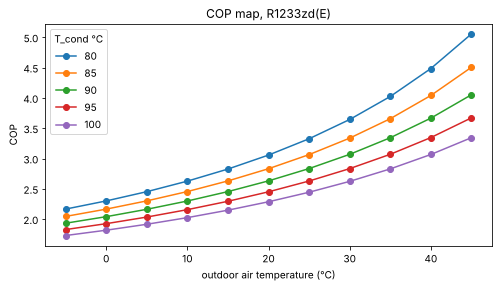

In [7]:
nw, parts = build_heat_pump("R1233zd(E)")
rows = []
for T_cond in [80, 85, 90, 95, 100]:
    for T_amb in range(-5, 46, 5):
        parts["c_cond"].set_attr(T=T_cond)
        parts["c_evap"].set_attr(T=T_amb - 8)
        nw.solve("design")
        rows.append({"T_cond": T_cond, "T_amb": T_amb, "COP": cop(parts) if nw.converged else np.nan})
cop_map = pd.DataFrame(rows)

ax = cop_map.pivot(index="T_amb", columns="T_cond", values="COP").plot(figsize=(8, 4), marker="o",
                                                                       title="COP map, R1233zd(E)")
ax.set_xlabel("outdoor air temperature (°C)"); ax.set_ylabel("COP"); ax.legend(title="T_cond °C");

## 4. Do we even need TESPy in the optimizer?

The ideal (Carnot) COP is `T_cond / (T_cond - T_evap)` in kelvin. Real
heat pumps get some fraction of that. If one fixed fraction fits the TESPy
map well, the optimizer can just use the formula.

best single Carnot fraction: 0.566
formula error: mean 3.2%, worst 8.1%


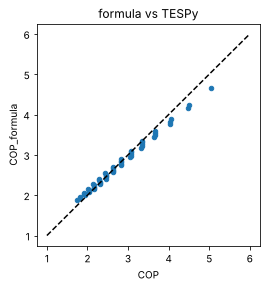

In [8]:
T_c = cop_map.T_cond + 273.15
T_e = cop_map.T_amb - 8 + 273.15
cop_map["COP_carnot"] = T_c / (T_c - T_e)
eta = (cop_map.COP / cop_map.COP_carnot).mean()
cop_map["COP_formula"] = eta * cop_map.COP_carnot
err = (cop_map.COP_formula - cop_map.COP) / cop_map.COP

print(f"best single Carnot fraction: {eta:.3f}")
print(f"formula error: mean {100 * err.abs().mean():.1f}%, worst {100 * err.abs().max():.1f}%")

ax = cop_map.plot.scatter("COP", "COP_formula", figsize=(4, 4), title="formula vs TESPy")
ax.plot([1, 6], [1, 6], "k--");

In [9]:
# where is the formula worst?
cop_map.assign(error_pct=100 * err).sort_values("error_pct", key=abs, ascending=False).head(5).round(2)

,T_cond,T_amb,COP,COP_carnot,COP_formula,error_pct
44,100,-5,1.73,3.30,1.87,8.14
10,80,45,5.06,8.21,4.65,-7.99
45,100,0,1.82,3.46,1.96,7.69
46,100,5,1.92,3.62,2.05,7.15
9,80,40,4.49,7.36,4.17,-7.08


The fraction of Carnot isn't constant: it drifts with the temperature
lift, so the formula is a few % off at the edges. For an hourly optimizer
that's probably fine, but since the TESPy map is cheap to compute I'll use
the map itself (interpolated) and keep the formula as a fallback.

What this simple model leaves out: superheat, subcooling, the water and
air heat exchangers, and part-load behaviour. Real COPs will be lower.
TESPy can do all of that, which is a next step if it matters.

## Save for the PyPSA notebook
COP vs outdoor temperature at 90 °C condensing (85 °C supply water).

In [10]:
out = cop_map[cop_map.T_cond == 90][["T_amb", "COP"]]
out.to_csv(config.DATA_DIR / "cop_map.csv", index=False)
print("saved", config.DATA_DIR / "cop_map.csv")
out.round(2).T

saved /home/user/energy_dt_ml/notebooks/../data/cop_map.csv


,22,23,24,25,26,27,28,29,30,31,32
T_amb,-5.00,0.00,5.00,10.0,15.00,20.00,25.00,30.00,35.00,40.00,45.00
COP,1.93,2.04,2.16,2.3,2.45,2.63,2.83,3.07,3.34,3.67,4.05
